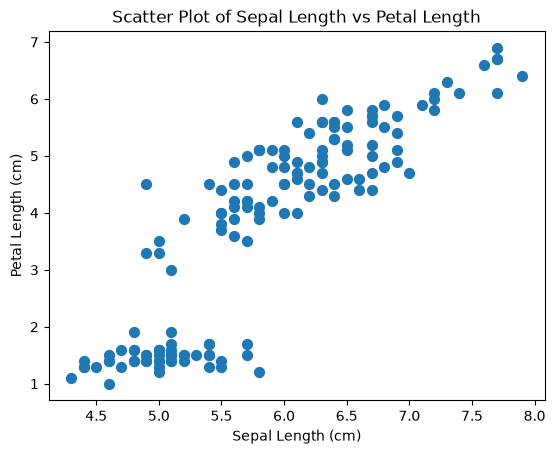

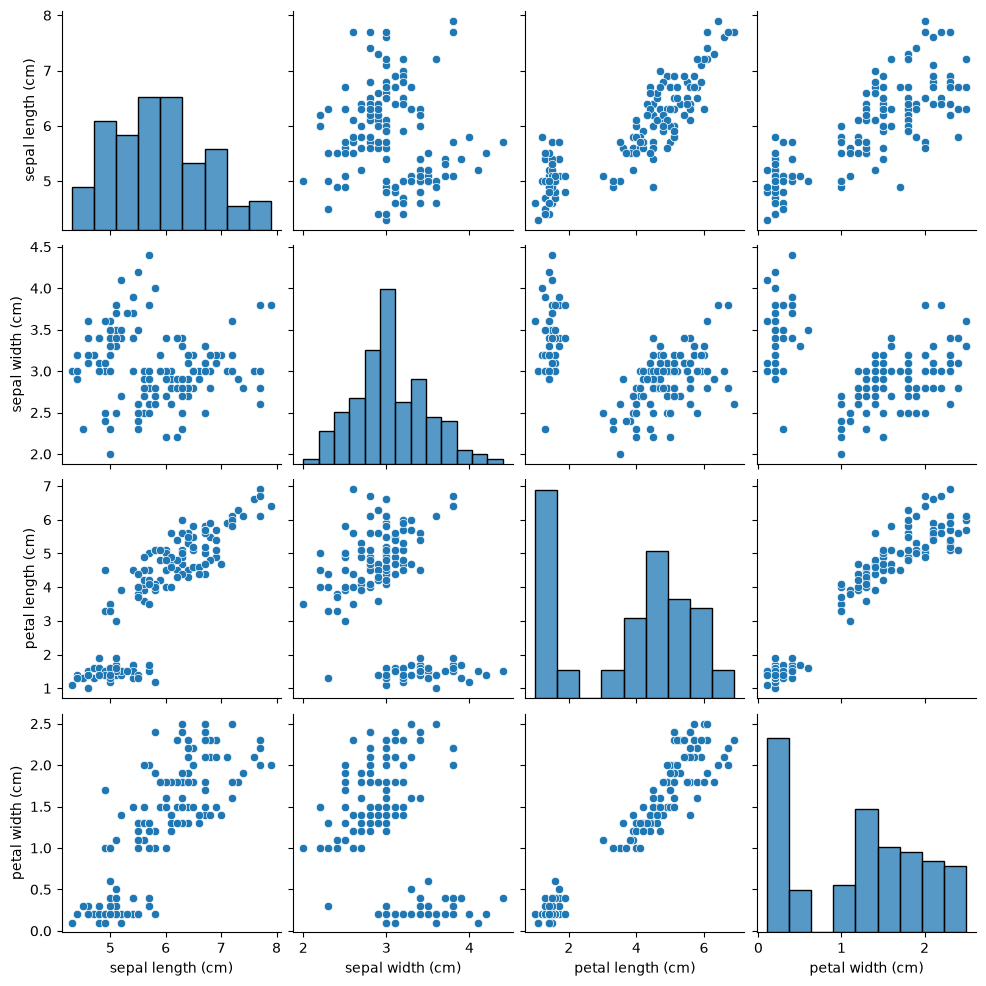

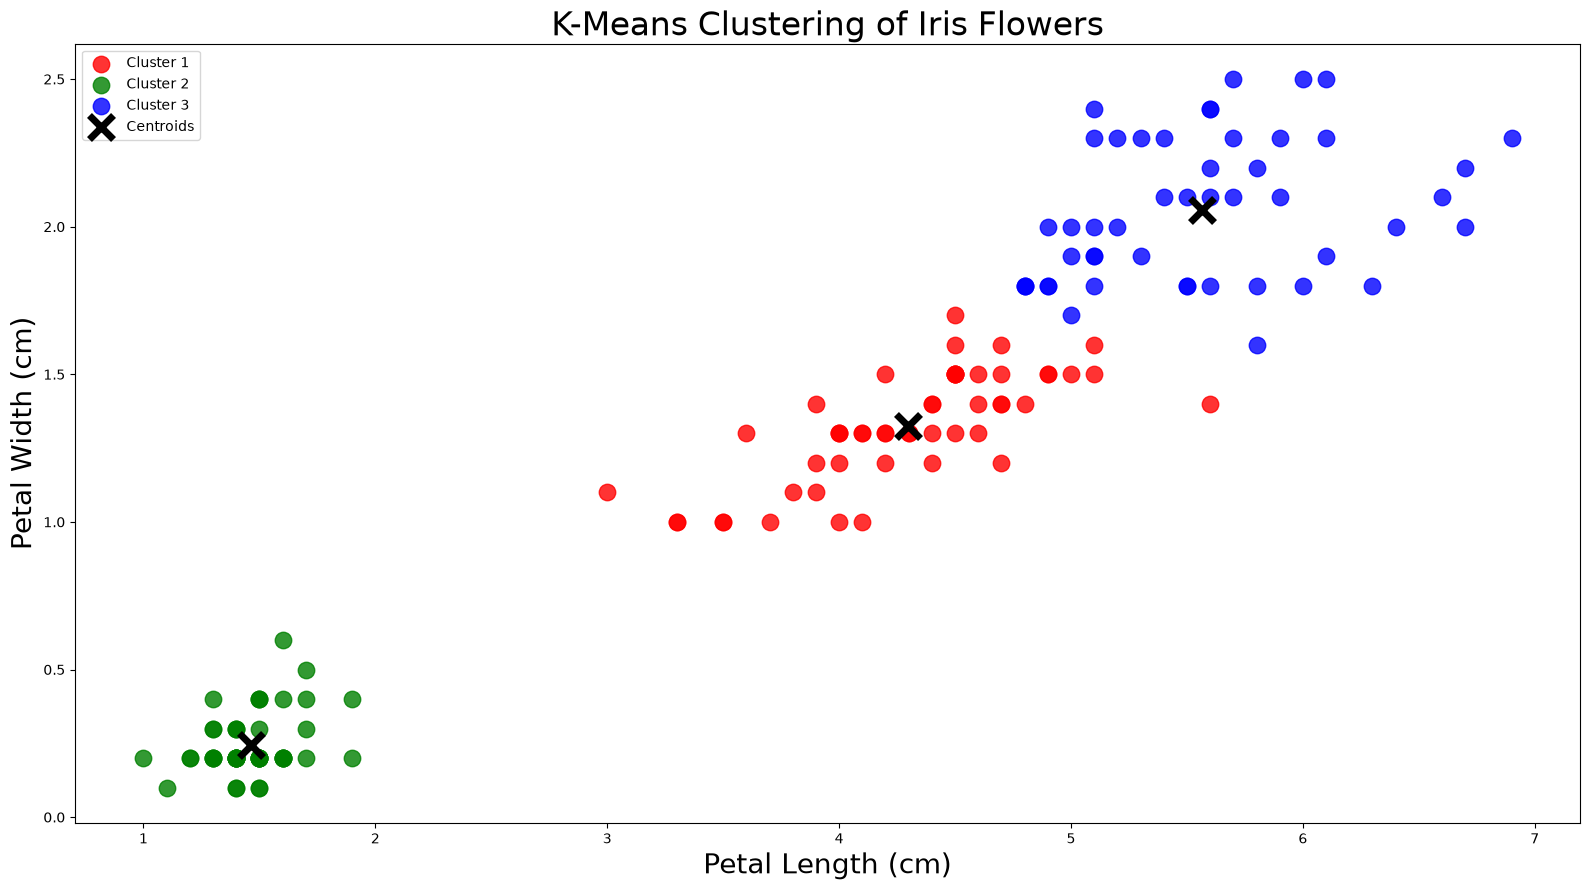

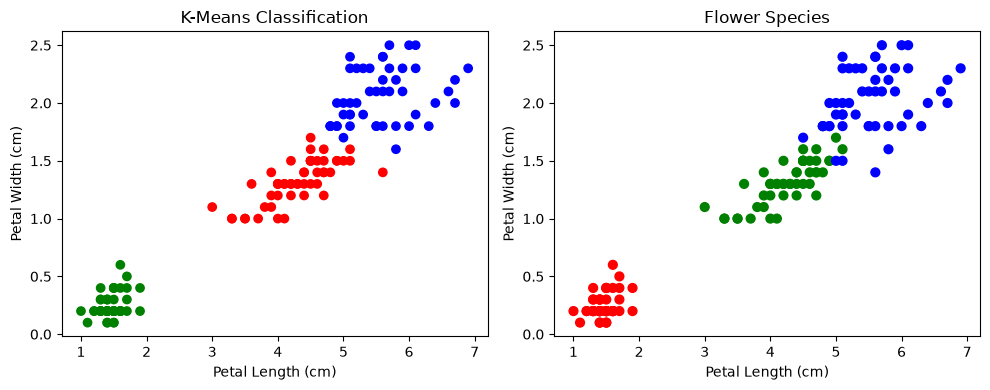

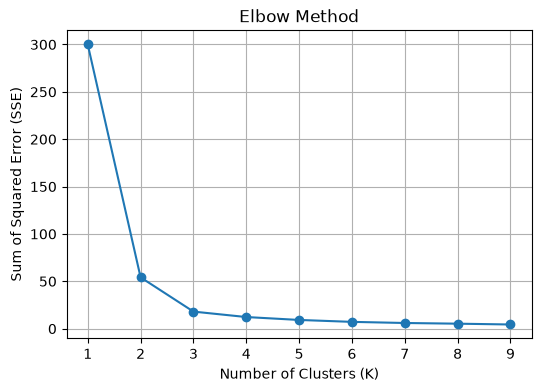

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.datasets import load_iris
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['flower'] = iris.target
plt.figure()
plt.scatter(df['sepal length (cm)'], df['petal length (cm)'], s=50)
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Petal Length (cm)')
plt.title('Scatter Plot of Sepal Length vs Petal Length')
plt.show()
sns.pairplot(df[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']])
plt.show()
df.drop(['sepal length (cm)', 'sepal width (cm)', 'flower'], axis='columns', inplace=True)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
kmeans = KMeans(n_clusters=3, random_state=1, n_init=10)
kmeans.fit(X_scaled)
labels = kmeans.labels_
centroids = kmeans.cluster_centers_
centroids_cm = scaler.inverse_transform(centroids)
colormap = np.array(['r', 'g', 'b'])
fig, ax = plt.subplots(figsize=(16, 9), facecolor='white')
for i in range(3):
    ax.scatter(df.loc[labels == i, 'petal length (cm)'],
               df.loc[labels == i, 'petal width (cm)'],
               c=colormap[i],
               s=140,
               alpha=0.8,
               label=f'Cluster {i+1}')
ax.scatter(centroids_cm[:, 0], centroids_cm[:, 1], s=300, marker='x', c='k', linewidths=5,
label='Centroids')
ax.set_xlabel('Petal Length (cm)', fontsize=20)
ax.set_ylabel('Petal Width (cm)', fontsize=20)
ax.set_title('K-Means Clustering of Iris Flowers', fontsize=24)
ax.legend()
fig.tight_layout()
plt.show()  
flower = iris.target
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.scatter(df['petal length (cm)'], df['petal width (cm)'], c=colormap[labels])
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('K-Means Classification')
plt.subplot(1, 2, 2)
plt.scatter(df['petal length (cm)'], df['petal width (cm)'], c=colormap[flower], s=40)
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('Flower Species')
plt.tight_layout()
plt.show()   
sse = []
k_rng = range(1, 10)
for k in k_rng:
    km = KMeans(n_clusters=k, random_state=1, n_init=10)
    km.fit(X_scaled)
    sse.append(km.inertia_)
plt.figure(figsize=(6, 4))
plt.plot(k_rng, sse, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Sum of Squared Error (SSE)')
plt.title('Elbow Method')
plt.grid(True)
plt.show()   